# 701 — Random Forest pour identifier l’utilisateur

Ce notebook utilise `data/processed/1clean/cleaned_train.csv` et `cleaned_test.csv`. Il compare des réglages de Random Forest avec des prédictions out-of-fold sur trois répétitions d'une validation stratifiée à quatre plis, choisit le réglage au meilleur F1 macro moyen, puis entraîne le modèle final et crée un fichier de soumission.

**Le test n'a pas d'étiquette `util`.** La précision, le rappel et le F1 ci-dessous sont donc des métriques de validation calculées uniquement sur le train; aucune métrique de performance test ne peut être donnée avant de recevoir les vraies étiquettes.

## Analyse du premier essai CNN

Le notebook CNN déjà exécuté a donné, sur une validation interne, un F1 macro de **0,3125**, un F1 pondéré de **0,3595** et une accuracy de **0,3765**. Sur le même découpage 80/20 (graine 42), un Random Forest de référence entraîné sur toutes les variables a obtenu un F1 macro de **0,8131** et une accuracy de **0,8643**. Cela soutient l'abandon du CNN 1D : les colonnes représentent des compteurs tabulaires, pas des voisins temporels. Ces résultats ne sont pas le score Kaggle, car le jeu de test n'est pas étiqueté.

Une comparaison out-of-fold additionnelle a testé plusieurs options sur six répétitions. Le meilleur résultat moyen observé garde les variables, utilise `max_features='sqrt'`, `min_samples_leaf=2` et `class_weight='balanced_subsample'` : F1 macro moyen **0,8500** (écart-type ≈ **0,0055**), accuracy moyenne **0,8731**. Le réglage proche `class_weight='balanced'` a obtenu un F1 macro moyen de **0,8484** avec un écart-type inférieur (**0,0035**); les résultats sont proches, mais le premier maximise le F1 macro moyen parmi les essais. Le modèle top-128 par score ANOVA a obtenu un F1 macro moyen de **0,8167** sur les six répétitions : réduire les dimensions a ici écarté du signal utile. On garde donc les variables non constantes plutôt que de forcer une réduction à 128.

Un score d'entraînement proche de 1 indique que les arbres peuvent mémoriser les sessions; il ne suffit pas à juger la généralisation. Nous utilisons des feuilles minimales de 2 observations et surtout des prédictions out-of-fold pour sélectionner les paramètres. Le choix final privilégie une performance de validation stable, sans prétendre éliminer tout surapprentissage.

## 1. Paramètres, imports et chargement des données

In [1]:
from pathlib import Path
import sys
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import SelectKBest, VarianceThreshold, f_classif
from sklearn.metrics import accuracy_score, precision_recall_fscore_support
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import Pipeline

SEED = 42
CV_SEEDS = (42, 2026, 7, 11, 99, 1234)
N_SPLITS = 4
N_ESTIMATORS_CV = 300
N_ESTIMATORS_FINAL = 500
TOP_K_REDUCTION = 128
N_JOBS = -1
TARGET = "util"

sns.set_theme(style="whitegrid")
print("Python kernel:", sys.executable, sys.version.split()[0])

def find_project_root(start: Path) -> Path:
    for candidate in (start, *start.parents):
        if (candidate / "data" / "processed" / "1clean").is_dir():
            return candidate
    raise FileNotFoundError("Impossible de trouver data/processed/1clean depuis le répertoire courant.")

PROJECT_ROOT = find_project_root(Path.cwd().resolve())
DATA_DIR = PROJECT_ROOT / "data" / "processed" / "1clean"
train_df = pd.read_csv(DATA_DIR / "cleaned_train.csv", low_memory=False)
test_df = pd.read_csv(DATA_DIR / "cleaned_test.csv", low_memory=False)

if TARGET not in train_df:
    raise ValueError(f"La colonne cible {TARGET!r} est absente du train.")
if TARGET in test_df:
    raise ValueError("Le fichier test devrait être sans étiquette util.")

y = train_df[TARGET].astype(str)
X = train_df.drop(columns=[TARGET]).copy()
X_test = test_df.copy()

# Le temps maximal et la durée sont des doublons dans ces données préparées.
if "max_time" in X and "duration_seconds" in X and X["max_time"].equals(X["duration_seconds"]):
    X = X.drop(columns=["duration_seconds"])
    X_test = X_test.drop(columns=["duration_seconds"])

if list(X.columns) != list(X_test.columns):
    raise ValueError("Les caractéristiques train et test ne sont pas alignées.")
if X.isna().any().any() or X_test.isna().any().any():
    raise ValueError("Valeurs manquantes trouvées; vérifier le nettoyage avant le modèle.")
if not all(pd.api.types.is_numeric_dtype(dtype) for dtype in X.dtypes):
    raise TypeError("Les variables explicatives doivent toutes être numériques.")

print(f"Train: {X.shape[0]} sessions, {X.shape[1]} variables | test: {len(X_test)} sessions")
print(f"Classes: {y.nunique()} | effectif par classe: {y.value_counts().min()} à {y.value_counts().max()}")
print("Valeurs manquantes:", int(X.isna().sum().sum()), int(X_test.isna().sum().sum()))
display(train_df.head())

Python kernel: /Library/Developer/CommandLineTools/usr/bin/python3 3.9.6
Train: 3279 sessions, 764 variables | test: 324 sessions
Classes: 247 | effectif par classe: 4 à 75
Valeurs manquantes: 0 0


,util,n_tokens,n_actions,n_time_markers,max_time,duration_seconds,n_distinct_verbs,n_screens,n_distinct_screens,n_configs,...,screen__infologic.ventes.modules.VT_DEVIS_CONTRAT.home.DevisAccueilHomeView,screen__infologic.ventes.modules.VT_FACTURATION.EditFactureForm,screen__infologic.ventes.modules.VT_FACTURATION.FactureVteForm,screen__infologic.ventes.modules.VT_LIVRAISON.EditBonLivForm,screen__infologic.ventes.modules.VT_LIVRAISON.LivraisonForm,screen__infologic.ventes.modules.VT_LIVRAISON.ReeditBonLivParamActionForm,screen__infologic.ventes.modules.VT_TARIFICATION.TarBaseVTForm,screen__smsi_fournisseurs,screen__smsi_fournisseurs_contrats,screen__smsi_fournisseurs_services
0,nuh,3128,2514,614,2905,2905,19,191,7,7,...,0,0,0,0,0,0,0,0,0,0
1,muz,136,90,46,230,230,11,8,5,4,...,0,0,0,0,0,0,0,0,0,0
2,zrx,766,608,158,750,750,21,94,17,35,...,0,0,0,0,0,0,0,0,0,0
3,pou,1199,886,313,1445,1445,19,249,10,9,...,0,0,0,0,0,0,0,0,0,0
4,ald,233,173,60,275,275,14,21,8,7,...,0,0,0,0,0,0,0,0,0,0


## 2. Exploration concise et classes déséquilibrées

Chaque utilisateur a de 4 à 75 sessions. Les métriques macro sont donc importantes en complément des métriques pondérées. Pour le Random Forest, il n'est pas nécessaire de standardiser les compteurs.

Résumé du nombre de sessions par utilisateur:


,sessions par utilisateur
count,247.000000
mean,13.275304
std,8.862380
min,4.000000
25%,7.000000
50%,12.000000
75%,16.000000
max,75.000000


15 utilisateurs avec le plus de sessions:


,sessions
util,
skm,75
slq,71
cjr,46
flj,42
hjs,37
vfo,35
shh,34
nqg,34
fwf,33


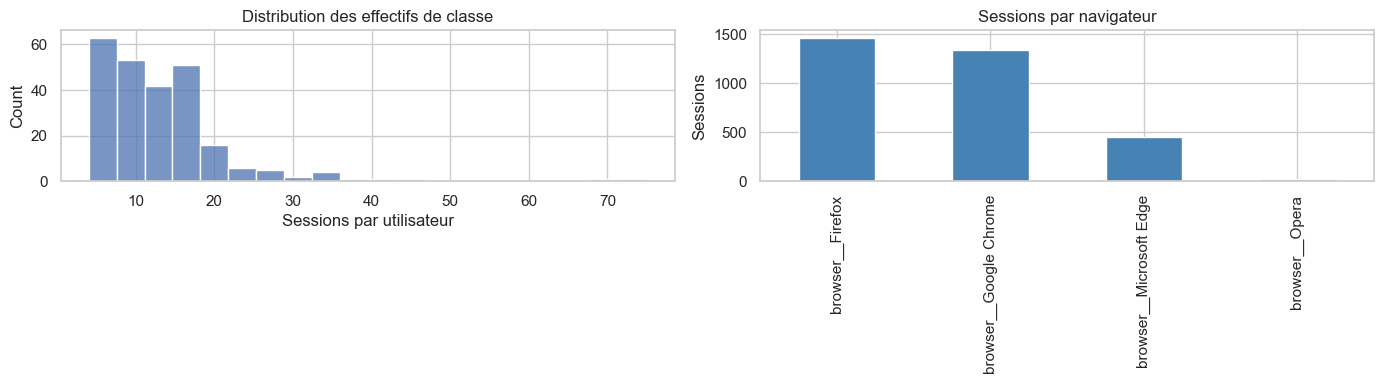

In [2]:
class_counts = y.value_counts()
print("Résumé du nombre de sessions par utilisateur:")
display(class_counts.describe().to_frame("sessions par utilisateur"))
print("15 utilisateurs avec le plus de sessions:")
display(class_counts.head(15).rename_axis("util").to_frame("sessions"))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(class_counts, bins=20, ax=axes[0])
axes[0].set(title="Distribution des effectifs de classe", xlabel="Sessions par utilisateur")
browser_columns = [column for column in X if column.startswith("browser__")]
if browser_columns:
    X[browser_columns].sum().sort_values(ascending=False).plot(kind="bar", ax=axes[1], color="steelblue")
    axes[1].set(title="Sessions par navigateur", ylabel="Sessions", xlabel="")
plt.tight_layout()
plt.show()

## 3. Comparer les réglages par validation croisée répétée

Le critère de sélection est le F1 macro, qui traite les utilisateurs équitablement malgré le déséquilibre. Chaque ligne du tableau est produite par prédictions out-of-fold : une session n'est prédite que par un modèle qui ne l'a pas utilisée pour l'entraînement. Quatre plis permettent d'inclure les classes qui ont seulement quatre sessions; leurs scores individuels restent néanmoins incertains.

La comparaison inclut une réduction à 128 caractéristiques ANOVA comme expérience, mais elle ne sera retenue que si elle améliore réellement les scores. Les étapes de sélection et de suppression des colonnes constantes sont intégrées dans le pipeline et refaites dans chaque pli, sans fuite de validation.

In [3]:
def safe_f_classif(features, labels):
    """Rank infinite ANOVA values safely while retaining their highest rank."""
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)
        scores, p_values = f_classif(features, labels)
    finite = scores[np.isfinite(scores)]
    replacement = finite.max() + 1.0 if finite.size else 1.0
    scores = np.nan_to_num(scores, nan=0.0, posinf=replacement, neginf=0.0)
    return scores, p_values

def make_pipeline(max_features, min_samples_leaf, class_weight, seed, top_k=None, max_depth=None, n_estimators=N_ESTIMATORS_CV):
    steps = [("remove_constant", VarianceThreshold(threshold=0.0))]
    if top_k is not None:
        steps.append(("select", SelectKBest(score_func=safe_f_classif, k=top_k)))
    steps.append((
        "rf",
        RandomForestClassifier(
            n_estimators=n_estimators,
            max_features=max_features,
            min_samples_leaf=min_samples_leaf,
            min_samples_split=2,
            max_depth=max_depth,
            class_weight=class_weight,
            random_state=seed,
            n_jobs=N_JOBS,
        ),
    ))
    return Pipeline(steps)

candidates = {
    "RF complet, équilibré, leaf=2": dict(max_features="sqrt", min_samples_leaf=2, class_weight="balanced_subsample", top_k=None),
    "RF complet, poids équilibrés globaux, leaf=2": dict(max_features="sqrt", min_samples_leaf=2, class_weight="balanced", top_k=None),
    "RF complet, max_features=0.3": dict(max_features=0.3, min_samples_leaf=2, class_weight=None, top_k=None),
    "RF complet, leaf=1 sans pondération": dict(max_features="sqrt", min_samples_leaf=1, class_weight=None, top_k=None),
    "RF complet, équilibré, leaf=3": dict(max_features="sqrt", min_samples_leaf=3, class_weight="balanced_subsample", top_k=None),
    "RF complet, équilibré, profondeur=20": dict(max_features="sqrt", min_samples_leaf=2, class_weight="balanced_subsample", max_depth=20, top_k=None),
    "RF top-128 ANOVA": dict(max_features="sqrt", min_samples_leaf=2, class_weight=None, top_k=TOP_K_REDUCTION),
}

repeat_rows = []
oof_by_candidate = {}
for candidate_name, parameters in candidates.items():
    candidate_seed_results = []
    oof_by_candidate[candidate_name] = {}
    for cv_seed in CV_SEEDS:
        cv = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=cv_seed)
        pipeline = make_pipeline(**parameters, seed=cv_seed)
        predictions = cross_val_predict(pipeline, X, y, cv=cv, n_jobs=1, method="predict")
        oof_by_candidate[candidate_name][cv_seed] = predictions
        p_macro, r_macro, f1_macro, _ = precision_recall_fscore_support(
            y, predictions, average="macro", zero_division=0
        )
        p_weighted, r_weighted, f1_weighted, _ = precision_recall_fscore_support(
            y, predictions, average="weighted", zero_division=0
        )
        scores = {
            "accuracy": accuracy_score(y, predictions),
            "precision_macro": p_macro,
            "recall_macro": r_macro,
            "f1_macro": f1_macro,
            "precision_weighted": p_weighted,
            "recall_weighted": r_weighted,
            "f1_weighted": f1_weighted,
        }
        candidate_seed_results.append(scores)
        repeat_rows.append({"Modèle": candidate_name, "Graine CV": cv_seed, **scores})
        print(candidate_name, cv_seed, "F1 macro:", round(f1_macro, 4))

repeat_results = pd.DataFrame(repeat_rows)
metric_columns = ["accuracy", "precision_macro", "recall_macro", "f1_macro", "precision_weighted", "recall_weighted", "f1_weighted"]
summary_rows = []
for candidate_name, group in repeat_results.groupby("Modèle", sort=False):
    row = {"Modèle": candidate_name}
    for metric in metric_columns:
        row[f"{metric}_moyenne"] = group[metric].mean()
        if metric == "f1_macro":
            row["f1_macro_ecart_type"] = group[metric].std(ddof=1)
    summary_rows.append(row)
cv_summary = pd.DataFrame(summary_rows).sort_values("f1_macro_moyenne", ascending=False).reset_index(drop=True)
display(cv_summary.round(4))
display(repeat_results.round(4))

RF complet, équilibré, leaf=2 42 F1 macro: 0.8409
RF complet, équilibré, leaf=2 2026 F1 macro: 0.8532
RF complet, équilibré, leaf=2 7 F1 macro: 0.8559
RF complet, équilibré, leaf=2 11 F1 macro: 0.8462
RF complet, équilibré, leaf=2 99 F1 macro: 0.851
RF complet, équilibré, leaf=2 1234 F1 macro: 0.8527
RF complet, poids équilibrés globaux, leaf=2 42 F1 macro: 0.846
RF complet, poids équilibrés globaux, leaf=2 2026 F1 macro: 0.848
RF complet, poids équilibrés globaux, leaf=2 7 F1 macro: 0.851
RF complet, poids équilibrés globaux, leaf=2 11 F1 macro: 0.8478
RF complet, poids équilibrés globaux, leaf=2 99 F1 macro: 0.8439
RF complet, poids équilibrés globaux, leaf=2 1234 F1 macro: 0.8536
RF complet, max_features=0.3 42 F1 macro: 0.833
RF complet, max_features=0.3 2026 F1 macro: 0.8326
RF complet, max_features=0.3 7 F1 macro: 0.8323
RF complet, max_features=0.3 11 F1 macro: 0.8274
RF complet, max_features=0.3 99 F1 macro: 0.8358
RF complet, max_features=0.3 1234 F1 macro: 0.8414
RF complet, 

,Modèle,accuracy_moyenne,precision_macro_moyenne,recall_macro_moyenne,f1_macro_moyenne,f1_macro_ecart_type,precision_weighted_moyenne,recall_weighted_moyenne,f1_weighted_moyenne
0,"RF complet, équilibré, leaf=2",0.8731,0.8773,0.8437,0.8500,0.0055,0.8809,0.8731,0.8699
1,"RF complet, poids équilibrés globaux, leaf=2",0.8710,0.8758,0.8411,0.8484,0.0035,0.8784,0.8710,0.8677
2,"RF complet, équilibré, leaf=3",0.8662,0.8677,0.8447,0.8457,0.0051,0.8768,0.8662,0.8642
3,"RF complet, max_features=0.3",0.8649,0.8772,0.8197,0.8338,0.0046,0.8727,0.8649,0.8595
4,"RF complet, leaf=1 sans pondération",0.8587,0.8698,0.8091,0.8245,0.0054,0.8643,0.8587,0.8513
5,"RF complet, équilibré, profondeur=20",0.8448,0.8470,0.8267,0.8230,0.0066,0.8612,0.8448,0.8426
6,RF top-128 ANOVA,0.8492,0.8684,0.7994,0.8167,0.0094,0.8583,0.8492,0.8420


,Modèle,Graine CV,accuracy,precision_macro,recall_macro,f1_macro,precision_weighted,recall_weighted,f1_weighted
0,"RF complet, équilibré, leaf=2",42,0.8701,0.8659,0.8352,0.8409,0.8760,0.8701,0.8661
1,"RF complet, équilibré, leaf=2",2026,0.8740,0.8784,0.8481,0.8532,0.8807,0.8740,0.8708
2,"RF complet, équilibré, leaf=2",7,0.8786,0.8852,0.8514,0.8559,0.8872,0.8786,0.8753
3,"RF complet, équilibré, leaf=2",11,0.8695,0.8756,0.8383,0.8462,0.8782,0.8695,0.8668
4,"RF complet, équilibré, leaf=2",99,0.8747,0.8774,0.8433,0.8510,0.8818,0.8747,0.8711
5,"RF complet, équilibré, leaf=2",1234,0.8719,0.8814,0.8463,0.8527,0.8813,0.8719,0.8693
6,"RF complet, poids équilibrés globaux, leaf=2",42,0.8695,0.8754,0.8383,0.8460,0.8779,0.8695,0.8661
7,"RF complet, poids équilibrés globaux, leaf=2",2026,0.8704,0.8751,0.8421,0.8480,0.8769,0.8704,0.8668
8,"RF complet, poids équilibrés globaux, leaf=2",7,0.8719,0.8791,0.8424,0.8510,0.8801,0.8719,0.8691
9,"RF complet, poids équilibrés globaux, leaf=2",11,0.8695,0.8766,0.8389,0.8478,0.8777,0.8695,0.8669


## 4. Modèle choisi, vérification de généralisation et importance des variables

Le modèle est sélectionné automatiquement par F1 macro moyen sur les répétitions; le F1 pondéré, le rappel et la précision restent visibles pour juger le compromis. Le tableau ne correspond pas à une validation finale indépendante après sélection, mais à l'estimation out-of-fold utilisée pour le choix. La dispersion entre graines donne un indice de stabilité, pas un intervalle de confiance formel.

Modèle retenu: RF complet, équilibré, leaf=2
Paramètres: {'max_features': 'sqrt', 'min_samples_leaf': 2, 'class_weight': 'balanced_subsample', 'top_k': None}
F1 macro moyen: 0.8500 ± 0.0055
Classes avec le plus petit support (leurs scores sont les moins stables):


,util,precision,recall,f1,support
86,itt,0.000,0.00,0.000,4
89,jew,0.333,0.50,0.400,4
9,bez,0.600,0.75,0.667,4
112,lra,1.000,0.50,0.667,4
161,rff,1.000,0.50,0.667,4
6,azn,0.800,1.00,0.889,4
27,crn,1.000,1.00,1.000,4
65,fyg,1.000,1.00,1.000,4
93,jkt,1.000,1.00,1.000,4
240,zll,1.000,1.00,1.000,4


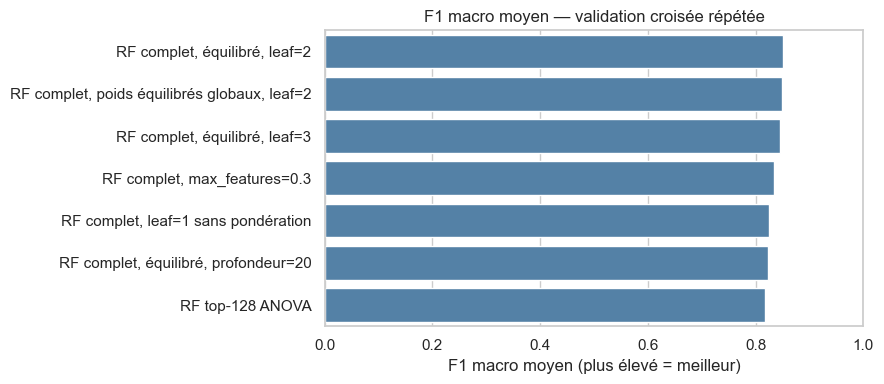

In [4]:
best_name = cv_summary.loc[0, "Modèle"]
best_parameters = candidates[best_name]
best_cv_row = cv_summary.iloc[0]
print("Modèle retenu:", best_name)
print("Paramètres:", best_parameters)
print(f"F1 macro moyen: {best_cv_row['f1_macro_moyenne']:.4f} ± {best_cv_row['f1_macro_ecart_type']:.4f}")

best_seed = CV_SEEDS[1]
best_oof_predictions = oof_by_candidate[best_name][best_seed]
per_class = precision_recall_fscore_support(y, best_oof_predictions, labels=np.unique(y), zero_division=0)
per_class_table = pd.DataFrame({
    "util": np.unique(y),
    "precision": per_class[0],
    "recall": per_class[1],
    "f1": per_class[2],
    "support": per_class[3],
}).sort_values(["support", "f1"], ascending=[True, True])
print("Classes avec le plus petit support (leurs scores sont les moins stables):")
display(per_class_table.head(15).round(3))

plt.figure(figsize=(9, 4))
sns.barplot(data=cv_summary, x="f1_macro_moyenne", y="Modèle", color="steelblue")
plt.xlim(0, 1)
plt.title("F1 macro moyen — validation croisée répétée")
plt.xlabel("F1 macro moyen (plus élevé = meilleur)")
plt.ylabel("")
plt.tight_layout()
plt.show()

## 5. Entraînement final sur tout le train et soumission test

On ajuste le pipeline choisi sur toutes les sessions étiquetées puis on prédit `cleaned_test.csv`. `util` est exclusivement une cible, jamais une entrée. Le fichier généré est `data/processed/1clean/701_random_forest_submission.csv`.

Prédictions test: 324 | classes prédites: 203
Fichier: /Users/macairm1/Desktop/3AECLM2/BE/ML & DS/BE_MachineLearning/data/processed/1clean/701_random_forest_submission.csv


,RowId,prediction
0,1,hzx
1,2,prb
2,3,jmq
3,4,psg
4,5,cvw
5,6,ald
6,7,nuh
7,8,lgz
8,9,nfh
9,10,xvr


,variable,importance_gini
24,action__Clic sur une grille d'historique de re...,0.019014
43,action__Raccourci,0.018742
45,action__Retour sur un écran,0.017003
17,action__Affichage d'un toast,0.016922
37,action__Filtrage / Tri,0.016738
27,action__Double-clic,0.015706
38,action__Lancement d'un tableau de bord,0.014346
567,screen__infologic.core.gui.controllers.BlankCo...,0.013381
47,action__Sélection d'un flag,0.013215
243,config__INSTALLATEUR,0.012765


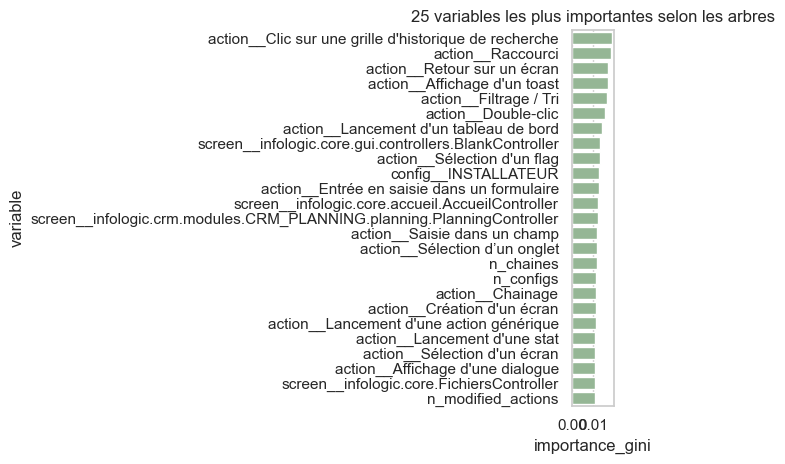

In [5]:
final_pipeline = make_pipeline(
    **best_parameters,
    seed=SEED,
    n_estimators=N_ESTIMATORS_FINAL,
)
final_pipeline.fit(X, y)
test_predictions = final_pipeline.predict(X_test)

submission = pd.DataFrame({
    "RowId": np.arange(1, len(test_predictions) + 1),
    "prediction": test_predictions,
})
submission_path = DATA_DIR / "701_random_forest_submission.csv"
submission.to_csv(submission_path, index=False)
assert len(submission) == len(test_df)
assert submission["RowId"].tolist() == list(range(1, len(test_df) + 1))
assert set(submission["prediction"]).issubset(set(y.unique()))
print("Prédictions test:", len(submission), "| classes prédites:", submission["prediction"].nunique())
print("Fichier:", submission_path)
display(submission.head(10))

# Importance Gini pour inspection, pas une preuve de causalité ni un test statistique.
forest = final_pipeline.named_steps["rf"]
feature_names = X.columns[final_pipeline.named_steps["remove_constant"].get_support()]
if "select" in final_pipeline.named_steps:
    feature_names = feature_names[final_pipeline.named_steps["select"].get_support()]
importance = pd.DataFrame({"variable": feature_names, "importance_gini": forest.feature_importances_})
importance = importance.sort_values("importance_gini", ascending=False).head(25)
display(importance)
sns.barplot(data=importance, x="importance_gini", y="variable", color="darkseagreen")
plt.title("25 variables les plus importantes selon les arbres")
plt.tight_layout()
plt.show()

## Conclusion

- Les scores à rapporter sont les moyennes out-of-fold du tableau de comparaison, particulièrement le F1 macro et le F1 pondéré.
- La meilleure option observée conserve l'ensemble des caractéristiques numériques non constantes; la réduction top-128 a baissé le F1 macro. Réduire le nombre de colonnes n'est pas automatiquement une amélioration.
- `min_samples_leaf=2` réduit la mémorisation par rapport aux feuilles d'une seule session, et `balanced_subsample` aide les classes rares. Les scores par utilisateur restent moins fiables lorsque seulement quelques sessions sont disponibles.
- Les mesures test restent impossibles sans vérités terrain. Le fichier de soumission contient uniquement les prédictions du modèle final.